![](img/banner.png)

# Bayesian Decision Theory

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

This page follows chapter 2 of *Pattern Classification* by Duda, Hart, and Stork
({cite}`Duda2000`), including its figures and the fish example. The estimates that fill in the
densities come from the [MLE page](MLE-Introduction.ipynb); the geometry of the Gaussian case is
worked out on the [Mahalanobis distance](Mahalanobis-Distance.ipynb) page, and the naive
assumption that makes the densities tractable is the subject of
[Naive Bayes](Naive-Bayes.ipynb).

**Learning objectives.** By the end you should be able to

1. write Bayes' formula for a classification problem and say which factor is a prior, a
   likelihood, an evidence and a posterior;
2. define a loss matrix, the conditional risk, and show that the zero-one loss gives the
   minimum error rate rule;
3. derive the discriminant function for Gaussian classes in the three cases of Duda's chapter —
   isotropic, equal, and arbitrary covariance matrices;
4. say what the decision boundary looks like in each case: a hyperplane orthogonal to the line
   between the means, a general hyperplane, or a quadric surface;
5. read the geometry off the eigenvalues of the covariance matrix.


## Introduction
- **Bayesian Decision Theory** is a statistical approach to pattern classification.
- It quantifies tradeoffs between classification decisions using probabilities and costs.
- Assumes all relevant probabilities are known.
- Example: Classifying fish (sea bass vs. salmon) based on features like lightness.

---

### Key Concepts
- **State of Nature** ($ \omega $): Represents the true category (e.g., sea bass or salmon).
- **Prior Probability** ($ P(\omega_j) $): Probability of a category before observing any data.
- **Class-Conditional Probability Density** ($ p(\mathbf{x} \mid \omega_j) $): Probability density of the observation $ \mathbf{x} $ given category $ \omega_j $.
- **Posterior Probability** ($ P(\omega_j \mid \mathbf{x}) $): Probability of category $ \omega_j $ after observing the features $ \mathbf{x} $.

---

### Bayes' Formula
- Bayes' Theorem:

  $$
  P(\omega_j \mid \mathbf{x}) = \frac{p(\mathbf{x} \mid \omega_j)\,P(\omega_j)}{p(\mathbf{x})}
  $$

  that is, **posterior** = likelihood × prior / evidence. The **evidence**
  ($ p(\mathbf{x}) $) is the normalising constant, and it is often ignored in classification
  because it is the same for every class.

  $$
  p(\mathbf{x}) = \sum_{j=1}^c p(\mathbf{x} \mid \omega_j)\,P(\omega_j)
  $$

---

The fish example below is one-dimensional: there the observation $\mathbf{x}$ is a single
feature $x$, the lightness of the fish, and $p(x \mid \omega_j)$ is a curve rather than a
surface.


### Reading the Formula

It is the product of **likelihood** and **prior** that decides the posterior; the **evidence**
$p(\mathbf{x})$ is only a scale factor, present to make the posteriors sum to one. The
likelihood $p(\mathbf{x} \mid \omega_j)$ is so called because, other things being equal, the
class for which it is large is the more likely one.

Figures 2.1 and 2.2 show the two halves of the argument for the fish: the class-conditional
densities, and the posteriors they produce with priors $P(\omega_1) = 2/3$ and
$P(\omega_2) = 1/3$.

![Figure 2.1](img/Duda-Figure-2.1.png)

**Figure 2.1**: hypothetical class-conditional densities for the lightness of sea bass
($\omega_1$) and salmon ($\omega_2$). Each curve is a density, so the area under it is 1.

![Figure 2.2](img/Duda-Figure-2.2.png)

**Figure 2.2**: the posteriors for the densities of Figure 2.1 with $P(\omega_1) = 2/3$ and
$P(\omega_2) = 1/3$. At $x = 14$ the posterior of $\omega_2$ is about $0.08$ and that of
$\omega_1$ about $0.92$; at every $x$ the two posteriors sum to $1$.


## Risk and Decision Rules

### Loss and Conditional Risk

The minimum-error rule is a special case of a more general criterion. Let
$\alpha_1,\dots,\alpha_a$ be the actions available — for classification, "decide $\omega_i$" —
and let $\lambda_{ij}$ be the **loss** of taking action $\alpha_i$ when the true class is
$\omega_j$. The **conditional risk** of action $\alpha_i$ for an observation $\mathbf{x}$ is

$$
R(\alpha_i \mid \mathbf{x}) = \sum_{j=1}^{c} \lambda_{ij}\,P(\omega_j \mid \mathbf{x}),
$$

and the Bayes decision rule selects the action of least risk:

$$
\text{decide } \alpha_i \quad \text{where} \quad i = \arg\min_{i} R(\alpha_i \mid \mathbf{x}).
$$

The **zero-one loss** sets $\lambda_{ij} = 0$ when $i = j$ and $1$ otherwise, that is, it prices
every error the same. Its conditional risk is the probability of being wrong,

$$
R(\alpha_i \mid \mathbf{x}) = \sum_{j \neq i} P(\omega_j \mid \mathbf{x}) = 1 - P(\omega_i \mid \mathbf{x}),
$$

so minimising the risk is the same as maximising the posterior. Unequal losses — a missed
disease costing more than a false alarm — simply move the decision threshold; they do not change
the machinery.


### Minimum Error Rate Classification

*  Decide $\omega_1$ if $P(\omega_1 \mid \mathbf{x}) > P(\omega_2 \mid \mathbf{x})$, otherwise
   decide $\omega_2$.
*  Equivalently, since the evidence is common to both classes, decide $\omega_1$ if

   $$
   p(\mathbf{x} \mid \omega_1)\,P(\omega_1) > p(\mathbf{x} \mid \omega_2)\,P(\omega_2).
   $$

*  The probability of error for a given observation is

   $$
   P(\text{error} \mid \mathbf{x}) = \min\left[P(\omega_1 \mid \mathbf{x}),\; P(\omega_2 \mid \mathbf{x})\right].
   $$


### Special Cases

Two cases show which factor drives the decision.

1.  If $p(\mathbf{x} \mid \omega_1) = p(\mathbf{x} \mid \omega_2)$, the observation is equally
    likely under both classes and tells us nothing; the decision rests entirely on the
    **priors**.
2.  If $P(\omega_1) = P(\omega_2)$, the classes are equally probable a priori and the decision
    rests entirely on the **likelihoods**.

In general both matter, and the rule $g_i(\mathbf{x}) = p(\mathbf{x} \mid \omega_i)P(\omega_i)$
combines them; that combination is what minimises the probability of error.


### More Than Two Classes

With $c > 2$ classes the same rule applies unchanged: assign $\mathbf{x}$ to the class that
maximises the posterior, which — as shown above — is the action of least risk under the
zero-one loss:

$$
\text{decide } \omega_i \quad\text{where}\quad P(\omega_i \mid \mathbf{x}) > P(\omega_j \mid \mathbf{x})
\quad \text{for all } j \neq i.
$$

For each class we compute one posterior, and the regions $\mathcal{R}_i$ where class $i$ wins are
separated by the surfaces $P(\omega_i \mid \mathbf{x}) = P(\omega_j \mid \mathbf{x})$.


## Discriminant Functions

A **discriminant function** $g_i(\mathbf{x})$ is any function whose value is largest for the class
we want to choose; the classifier computes one per class and picks the maximum.

$$
\text{decide } \omega_i \quad\text{if}\quad g_i(\mathbf{x}) > g_j(\mathbf{x}) \text{ for all } j \neq i.
$$

For minimum error rate the obvious choice is the posterior itself,

$$
g_i(\mathbf{x}) = P(\omega_i \mid \mathbf{x}),
$$

and because the evidence is a common positive factor we may use the numerator,

$$
g_i(\mathbf{x}) = p(\mathbf{x} \mid \omega_i)\,P(\omega_i),
$$

or its logarithm, which turns the product into a sum and the exponential of a Gaussian into a
quadratic form:

$$
g_i(\mathbf{x}) = \ln p(\mathbf{x} \mid \omega_i) + \ln P(\omega_i).
$$

Any monotone function of a discriminant is a discriminant, and any positive multiple or additive
constant may be dropped: the classification is unchanged. That freedom is what makes the
Gaussian case tractable below.

![](img/Duda-Figure-2.5.png)

Figure 2.5: the structure of a general statistical classifier — $d$ inputs, $c$ discriminant
functions, and a maximum selector. The arrows show the flow of information.


## The Normal Density

### Univariate Case

The **univariate normal density** is

$$
p(x) = \frac{1}{\sqrt{2\pi}\sigma}\exp\left[-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^{2}\right],
$$

with the **expected value** of $x$ (an average over the feature space)

$$
\mu = \mathbb{E}[x] = \int_{-\infty}^{\infty} x\,p(x)\,dx
$$

and the **variance**

$$
\sigma^2 = \mathbb{E}[(x-\mu)^2] = \int_{-\infty}^{\infty} (x-\mu)^2 p(x)\,dx .
$$

The univariate normal is completely specified by $\mu$ and $\sigma^2$; we write
$p(x) \sim N(\mu, \sigma^2)$. Samples cluster about the mean with a spread set by the **standard
deviation** $\sigma$ (Figure 2.7).

![Figure 2.7](img/Duda-Figure-2.7.png)

**Figure 2.7**: a univariate normal has roughly $95\%$ of its area inside
$|x-\mu| \le 2\sigma$; the peak value is $p(\mu) = 1/(\sqrt{2\pi}\sigma)$.


## The Multivariate Normal Density

$$
p(\mathbf{x}) = \frac{1}{(2\pi)^{d/2}|\boldsymbol{\Sigma}|^{1/2}}
\exp\left[-\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu})\right],
$$

where the **mean vector** $\boldsymbol{\mu}$ and the **covariance matrix** $\boldsymbol{\Sigma}$
replace the two scalars of the univariate case.

### Formal Definitions

$$
\boldsymbol{\mu} = \mathbb{E}[\mathbf{x}] = \int \mathbf{x}\,p(\mathbf{x})\,d\mathbf{x},
\qquad
\boldsymbol{\Sigma} = \mathbb{E}\left[(\mathbf{x}-\boldsymbol{\mu})(\mathbf{x}-\boldsymbol{\mu})^{\top}\right].
$$

The expected value of a vector or a matrix is taken componentwise: with $x_i$ the $i$-th
component of $\mathbf{x}$ and $\sigma_{ij}$ the $ij$-th component of $\boldsymbol{\Sigma}$,

$$
\mu_i = \mathbb{E}[x_i],
\qquad
\sigma_{ij} = \mathbb{E}[(x_i-\mu_i)(x_j-\mu_j)].
$$

### Properties of the Covariance Matrix

*  $\boldsymbol{\Sigma}$ is **symmetric** and **positive semidefinite**; we assume it is positive
   definite, so that $|\boldsymbol{\Sigma}| > 0$ and the inverse exists.
*  The diagonal element $\sigma_{ii}$ is the variance of $x_i$, that is $\sigma_i^2$.
*  The off-diagonal element $\sigma_{ij}$ is the covariance of $x_i$ and $x_j$; for the length
   and weight of a population of fish we would expect it to be positive.
*  If $x_i$ and $x_j$ are statistically independent then $\sigma_{ij} = 0$; if *all* off-diagonal
   elements vanish, $p(\mathbf{x})$ factorises into the product of univariate normal densities.

### Parameters and Geometry

The multivariate normal is completely specified by $d + d(d+1)/2$ parameters: the $d$ elements of
$\boldsymbol{\mu}$ and the $d(d+1)/2$ independent elements of $\boldsymbol{\Sigma}$.

Samples fall in a single cluster whose **centre** is $\boldsymbol{\mu}$ and whose **shape** is
$\boldsymbol{\Sigma}$. The loci of constant density are the **hyperellipsoids**

$$
(\mathbf{x}-\boldsymbol{\mu})^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu}) = \text{constant},
$$

whose principal axes are the **eigenvectors** of $\boldsymbol{\Sigma}$ and whose axis lengths
follow from the **eigenvalues**. The quadratic form itself is the squared
[Mahalanobis distance](Mahalanobis-Distance.ipynb) from $\mathbf{x}$ to
$\boldsymbol{\mu}$: contours of constant density are contours of constant Mahalanobis distance,
and the volume they enclose measures the scatter of the samples.

![Figure 2.9](img/Duda-Figure-2.9.png)

**Figure 2.9**: samples from a two-dimensional Gaussian lie in a cloud centred on
$\boldsymbol{\mu}$; the red ellipses are lines of equal probability density.


## Discriminant Functions for Normal Densities

### Case 1: Isotropic Covariance, $\boldsymbol{\Sigma}_i = \sigma^2\mathbf{I}$

The simplest case: all classes share the same spherical covariance. Then
$|\boldsymbol{\Sigma}_i| = \sigma^{2d}$ and $\boldsymbol{\Sigma}_i^{-1} = \mathbf{I}/\sigma^2$,
so the density and its logarithm are

$$
p(\mathbf{x} \mid \omega_i) = \frac{1}{(2\pi\sigma^2)^{d/2}}
\exp\left(-\frac{\|\mathbf{x}-\boldsymbol{\mu}_i\|^2}{2\sigma^2}\right),
\qquad
\ln p(\mathbf{x} \mid \omega_i) = -\frac{\|\mathbf{x}-\boldsymbol{\mu}_i\|^2}{2\sigma^2}
- \frac{d}{2}\ln(2\pi\sigma^2).
$$

Substituting into $g_i(\mathbf{x}) = \ln p(\mathbf{x} \mid \omega_i) + \ln P(\omega_i)$, and
dropping the term $\frac{d}{2}\ln(2\pi\sigma^2)$ because it is the same for every class:

$$
\boxed{g_i(\mathbf{x}) = -\frac{\|\mathbf{x}-\boldsymbol{\mu}_i\|^2}{2\sigma^2} + \ln P(\omega_i)}
$$

With equal priors the rule is "assign $\mathbf{x}$ to the nearest mean", with the Euclidean
distance scaled by $2\sigma^2$. With unequal priors, a point that is equally near two means is
given to the a priori more likely class, because $\ln P(\omega_i)$ is the tie-breaker.

### The Linear Form and the Boundary

Expanding the quadratic form,

$$
g_i(\mathbf{x}) = -\frac{1}{2\sigma^2}\left[\mathbf{x}^{\top}\mathbf{x}
- 2\boldsymbol{\mu}_i^{\top}\mathbf{x} + \boldsymbol{\mu}_i^{\top}\boldsymbol{\mu}_i\right]
+ \ln P(\omega_i).
$$

The term $\mathbf{x}^{\top}\mathbf{x}$ does not depend on $i$ and can be dropped as an additive
constant, which leaves a **linear** discriminant

$$
g_i(\mathbf{x}) = \mathbf{w}_i^{\top}\mathbf{x} + w_{i0},
\qquad
\mathbf{w}_i = \frac{\boldsymbol{\mu}_i}{\sigma^2},
\qquad
w_{i0} = -\frac{\boldsymbol{\mu}_i^{\top}\boldsymbol{\mu}_i}{2\sigma^2} + \ln P(\omega_i),
$$

where $w_{i0}$ is the **threshold** (or bias) of class $i$. A classifier built from linear
discriminants is a **linear machine**: its decision surfaces are pieces of hyperplanes, given by
$g_i(\mathbf{x}) = g_j(\mathbf{x})$ for the two classes whose posteriors are largest. For two
classes that equation reads

$$
\mathbf{w}^{\top}(\mathbf{x}-\mathbf{x}_0) = 0,
\qquad
\mathbf{w} = \boldsymbol{\mu}_i - \boldsymbol{\mu}_j,
\qquad
\mathbf{x}_0 = \frac{1}{2}(\boldsymbol{\mu}_i + \boldsymbol{\mu}_j)
- \frac{\sigma^2}{\|\boldsymbol{\mu}_i-\boldsymbol{\mu}_j\|^2}
  \ln\frac{P(\omega_i)}{P(\omega_j)}\,(\boldsymbol{\mu}_i-\boldsymbol{\mu}_j).
$$

So the boundary is a hyperplane through $\mathbf{x}_0$, orthogonal to
$\mathbf{w} = \boldsymbol{\mu}_i-\boldsymbol{\mu}_j$ — orthogonal, that is, to the line joining
the two means. With equal priors $\mathbf{x}_0$ is the midpoint and the boundary is the
perpendicular bisector of the segment between the means; with unequal priors it slides away from
the more likely mean, by an amount that is large when $\sigma^2$ is large compared with
$\|\boldsymbol{\mu}_i-\boldsymbol{\mu}_j\|^2$ and negligible when the means are far apart.

![Figure 2.10](img/Duda-Figure-2.10.png)

**Figure 2.10**: with equal isotropic covariances the class regions are separated by a
generalised hyperplane of $d-1$ dimensions, perpendicular to the line joining the means.

### Minimum Distance Classifier

If all priors are also equal, $\ln P(\omega_i)$ is an additive constant, and the rule reduces to
measuring the Euclidean distance $\|\mathbf{x}-\boldsymbol{\mu}_i\|$ and assigning the nearest
mean. This is the **minimum distance classifier**. Reading each mean as an ideal prototype of its
class makes it a **template-matching** procedure, and it is exactly the nearest-neighbour rule of
the previous chapter with one template per class instead of the whole training set.

### What a Hyperplane Looks Like in Two Dimensions

The equation $\mathbf{w}^{\top}(\mathbf{x}-\mathbf{x}_0) = 0$ says that the vector
$\mathbf{x}-\mathbf{x}_0$ is orthogonal to $\mathbf{w}$ for every point $\mathbf{x}$ of the
surface, so:

*  $\mathbf{w}$ is a **normal** to the surface and fixes its orientation;
*  $\mathbf{x}_0$ is one fixed point of the surface;
*  in $d = 2$ the surface is a line, and the equation becomes
   $w_1(x-x_{01}) + w_2(x-x_{02}) = 0$.

For example, with $\mathbf{w} = (2,1)^{\top}$ and $\mathbf{x}_0 = (1,1)^{\top}$ the line is
$2x + y - 3 = 0$. The next cell draws it together with the normal vector.


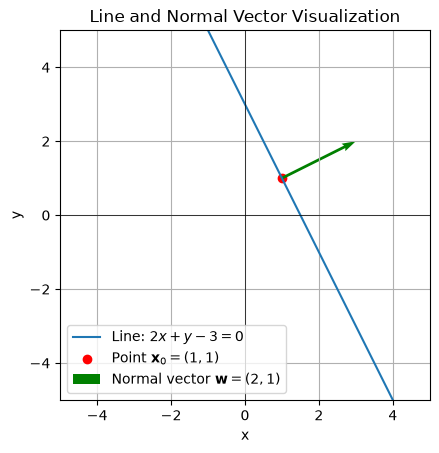

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Define the normal vector w and point x0
w = np.array([2, 1])  # Normal vector
x0 = np.array([1, 1])  # Point on the line

# Define the line equation: 2x + y - 3 = 0 => y = -2x + 3
x_values = np.linspace(-5, 5, 100)  # Range of x values
y_values = -2 * x_values + 3  # Corresponding y values

# Plot the line
plt.plot(x_values, y_values, label=r"Line: $2x + y - 3 = 0$")

# Plot the point x0
plt.scatter(x0[0], x0[1], color="red", label=r"Point $\mathbf{x}_0 = (1, 1)$")

# Plot the normal vector w starting from x0
plt.quiver(x0[0], x0[1], w[0], w[1], angles='xy', scale_units='xy', scale=1, color="green", label=r"Normal vector $\mathbf{w} = (2, 1)$")

# Add labels and legend
plt.xlabel("x")
plt.ylabel("y")
plt.axhline(0, color="black", linewidth=0.5)  # x-axis
plt.axvline(0, color="black", linewidth=0.5)  # y-axis
plt.grid(True)
plt.legend()
plt.title("Line and Normal Vector Visualization")
plt.xlim(-5, 5)  # Adjust x-axis limits
plt.ylim(-5, 5)  # Adjust y-axis limits
plt.gca().set_aspect("equal", adjustable="box")  # Equal aspect ratio
plt.show()

### Case 2: Equal but Arbitrary Covariance Matrices, $\boldsymbol{\Sigma}_i = \boldsymbol{\Sigma}$

When all classes share the same non-spherical covariance, the general discriminant

$$
g_i(\mathbf{x}) = -\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_i)^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu}_i)
+ \ln P(\omega_i),
$$

follows from the Gaussian after dropping $\ln|\boldsymbol{\Sigma}|$ and $\frac{d}{2}\ln(2\pi)$,
which are now common to all classes. Expanding the quadratic term (using that
$\boldsymbol{\Sigma}^{-1}$ is symmetric, so $\mathbf{x}^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i =
\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\mathbf{x}$):

$$
(\mathbf{x}-\boldsymbol{\mu}_i)^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu}_i)
= \mathbf{x}^{\top}\boldsymbol{\Sigma}^{-1}\mathbf{x}
- 2\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\mathbf{x}
+ \boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i .
$$

The first term does not depend on $i$ and is dropped; what remains is again linear,

$$
g_i(\mathbf{x}) = \mathbf{w}_i^{\top}\mathbf{x} + w_{i0},
\qquad
\mathbf{w}_i = \boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i,
\qquad
w_{i0} = -\frac{1}{2}\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i + \ln P(\omega_i),
$$

so the boundaries are hyperplanes. Setting $g_i(\mathbf{x}) = g_j(\mathbf{x})$:

$$
(\boldsymbol{\mu}_i-\boldsymbol{\mu}_j)^{\top}\boldsymbol{\Sigma}^{-1}\mathbf{x}
- \frac{1}{2}\left(\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i
- \boldsymbol{\mu}_j^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_j\right)
+ \ln\frac{P(\omega_i)}{P(\omega_j)} = 0 .
$$

### The Geometry of Case 2

Write the boundary as $\mathbf{w}^{\top}\mathbf{x} + w_0 = 0$ with

$$
\mathbf{w} = \boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_i-\boldsymbol{\mu}_j),
\qquad
w_0 = -\frac{1}{2}\left(\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_i
- \boldsymbol{\mu}_j^{\top}\boldsymbol{\Sigma}^{-1}\boldsymbol{\mu}_j\right)
+ \ln\frac{P(\omega_i)}{P(\omega_j)} .
$$

The normal $\mathbf{w}$ points along $\boldsymbol{\Sigma}^{-1}(\boldsymbol{\mu}_i-\boldsymbol{\mu}_j)$,
which in general is **not** the direction of $\boldsymbol{\mu}_i-\boldsymbol{\mu}_j$: the shared
covariance rotates the boundary. Only when $\boldsymbol{\Sigma}$ is proportional to
$\mathbf{I}$ do we recover Case 1. With equal priors the logarithm vanishes and the boundary
passes through $\mathbf{x}_0 = \frac{1}{2}(\boldsymbol{\mu}_i+\boldsymbol{\mu}_j)$, but it is not
perpendicular to the line between the means.

The surfaces of constant Mahalanobis distance from the two means are hyperellipsoids of the same
shape and orientation, one per class, because $\boldsymbol{\Sigma}$ is shared. They are linear
boundaries only because the quadratic terms $\mathbf{x}^{\top}\boldsymbol{\Sigma}^{-1}\mathbf{x}$
cancel in $g_i - g_j$.

![](img/Duda-Figure-2.12.png)

**Figure 2.12**: equal covariance matrices give linear boundaries that are not necessarily
perpendicular to the line joining the means; both classes are shown with the same ellipses of
equal density, and the boundary moves with the priors. The next figure shows it sliding as the priors change, for one-, two- and
three-dimensional spherical classes.


![Figure 2.11](img/Duda-Figure-2.11.png)

**Figure 2.11**: as the priors are changed, the decision boundary shifts; for sufficiently disparate priors the boundary will not lie between the means of these 1-, 2- and 3-dimensional spherical Gaussian distributions

### Case 3: Arbitrary Covariance Matrices, $\boldsymbol{\Sigma}_i$

The general case: each class has its own mean $\boldsymbol{\mu}_i$ and its own covariance
$\boldsymbol{\Sigma}_i$. Starting from

$$
g_i(\mathbf{x}) = \ln p(\mathbf{x} \mid \omega_i) + \ln P(\omega_i)
= -\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_i)^{\top}\boldsymbol{\Sigma}_i^{-1}(\mathbf{x}-\boldsymbol{\mu}_i)
- \frac{1}{2}\ln|\boldsymbol{\Sigma}_i| + \ln P(\omega_i),
$$

and expanding the quadratic form exactly as in Case 2, but now with $\boldsymbol{\Sigma}_i$:

$$
g_i(\mathbf{x}) = -\frac{1}{2}\mathbf{x}^{\top}\boldsymbol{\Sigma}_i^{-1}\mathbf{x}
+ \boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}_i^{-1}\mathbf{x}
- \frac{1}{2}\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}_i^{-1}\boldsymbol{\mu}_i
- \frac{1}{2}\ln|\boldsymbol{\Sigma}_i| + \ln P(\omega_i).
$$

This is a quadratic form in $\mathbf{x}$,

$$
g_i(\mathbf{x}) = \mathbf{x}^{\top}\mathbf{W}_i\mathbf{x} + \mathbf{w}_i^{\top}\mathbf{x} + w_{i0},
\qquad
\mathbf{W}_i = -\frac{1}{2}\boldsymbol{\Sigma}_i^{-1},
\qquad
\mathbf{w}_i = \boldsymbol{\Sigma}_i^{-1}\boldsymbol{\mu}_i,
$$

$$
w_{i0} = -\frac{1}{2}\boldsymbol{\mu}_i^{\top}\boldsymbol{\Sigma}_i^{-1}\boldsymbol{\mu}_i
- \frac{1}{2}\ln|\boldsymbol{\Sigma}_i| + \ln P(\omega_i).
$$

The difference from Case 2 is the term $-\frac{1}{2}\ln|\boldsymbol{\Sigma}_i|$: with unequal
covariances the volume of the class matters, and a diffuse class is penalised. The discriminant
is now quadratic in $\mathbf{x}$ and the boundary, given by $g_i(\mathbf{x}) = g_j(\mathbf{x})$,

$$
\mathbf{x}^{\top}(\mathbf{W}_i-\mathbf{W}_j)\mathbf{x}
+ (\mathbf{w}_i-\mathbf{w}_j)^{\top}\mathbf{x} + (w_{i0}-w_{j0}) = 0,
$$

does **not** lose its quadratic term, because $\mathbf{W}_i \neq \mathbf{W}_j$.


### What the Quadratic Boundaries Look Like

A surface of this kind is a **hyperquadric** — a hyperplane, a pair of hyperplanes, a
hypersphere, a hyperellipsoid, a hyperparaboloid or a hyperhyperboloid, depending on the
eigenvalues of $\mathbf{W}_i - \mathbf{W}_j$ and on the linear and constant terms. In two
dimensions those are a line, a pair of lines, a circle, an ellipse, a parabola and a
hyperbola. Every one of these shapes can
arise from two Gaussians, and conversely every hyperquadric is the Bayes boundary of some pair of
Gaussians.

![Figure 2.6](img/Duda-Figure-2.6.png)

**Figure 2.6**: a two-dimensional two-category Gaussian classifier with unequal covariances. The
two hyperbolas are the boundary, so the decision region $\mathcal{R}_2$ is not simply connected —
a reminder that "the" boundary may have several branches.

![Figure 2.14](img/Duda-Figure-2.14.png)

**Figure 2.14**: arbitrary Gaussians give hyperquadric boundaries; the four panels show an
ellipse, a hyperbola, a parabola and a pair of lines.

### More Than Two Classes

Extending the result to $c$ classes is straightforward, but one has to keep track of which two
classes are responsible for each piece of a boundary. Figure 2.16 shows the decision regions of a
four-class problem with Gaussian classes: even with four classes the regions are already
complicated, and the same theory still governs them.

![Figure 2.16](img/Duda-Figure-2.16.png)

**Figure 2.16**: the decision regions of four normal distributions.


---

### Exercise: Verifying Case 2 with Scikit-Learn

**Objective.** Reproduce the Case 2 boundary twice — once from the formula above and once from
`GaussianNB` — and check that they agree.

1.  **Generate data.** Two classes, 200 points each, both with covariance
    $\boldsymbol{\Sigma} = \begin{bmatrix} 2 & 1 \\ 1 & 2\end{bmatrix}$ and means
    $\boldsymbol{\mu}_1 = (2,3)^{\top}$, $\boldsymbol{\mu}_2 = (6,5)^{\top}$.
2.  **Theoretical boundary.** With $P(\omega_1) = P(\omega_2) = 0.5$, use

    $$
    g_i(\mathbf{x}) = -\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_i)^{\top}\boldsymbol{\Sigma}^{-1}(\mathbf{x}-\boldsymbol{\mu}_i) + \ln P(\omega_i)
    $$

    and draw the curve $g_1(\mathbf{x}) = g_2(\mathbf{x})$ on a grid with `plt.contour`.
3.  **Estimated boundary.** Fit `GaussianNB` on the 200 + 200 points and draw the boundary of its
    predictions on the same grid.
4.  **Compare.** Plot the two boundaries together, with the points, the line joining the two
    means, and its perpendicular bisector. The two boundaries should be close but not identical:
    `GaussianNB` estimates $\boldsymbol{\mu}_i$ and $\boldsymbol{\Sigma}_i$ from the sample, while
    step 2 uses the true parameters. The angle between the boundary normal and the line joining
    the means is the visible consequence of the shared covariance (Case 2).


## Summary

Bayesian decision theory turns probabilities into decisions.

*  The ingredients are the **priors** $P(\omega_i)$, the **class-conditional densities**
   $p(\mathbf{x} \mid \omega_i)$, the **posteriors** $P(\omega_i \mid \mathbf{x})$ and the
   **evidence** $p(\mathbf{x})$, which normalises the posteriors and cancels from every decision.
*  The general criterion is the **conditional risk** with a loss matrix $\lambda_{ij}$; the
   zero-one loss reduces it to the minimum error rate rule, "pick the largest posterior".
*  Any monotone function of the posterior is a valid **discriminant**; using the log turns the
   Gaussian into a quadratic form.
*  For Gaussian classes there are three regimes. Isotropic and equal covariances give linear
   discriminants and hyperplane boundaries; arbitrary covariances give quadratic discriminants
   and hyperquadric boundaries.
*  The quadratic form inside the Gaussian is the squared **Mahalanobis distance**, and the three
   regimes are exactly LDA, LDA with a general $\boldsymbol{\Sigma}$, and QDA.
*  Density parameters are estimated by maximum likelihood; when classes are too small to estimate
   a full covariance, the naive assumption (independent features) is the usual way out.

## References

{cite}`Duda2000`

Duda, R. O., Hart, P. E., & Stork, D. G. (2000). *Pattern Classification* (2nd ed.).
Wiley-Interscience, chapter 2.
